# 🧠 Complete Artificial Neural Networks (ANN) Masterclass: From Perceptron to Deep Learning Production Systems

### *A Comprehensive Theory-to-Practice Guide: Mathematics, Architecture, Activation Functions, Loss Functions, Optimizers, Regularization, and an End-to-End Hands-On Industry Project*

---

## 📌 Roadmap & Table of Contents
1. **Module 1: The Foundations — From Biological Neurons to the Perceptron**
   - 1.1 Biological vs. Artificial Neurons (McCulloch-Pitts Model)
   - 1.2 Frank Rosenblatt's Perceptron (1958) & Linear Combination
   - 1.3 The Perceptron Learning Algorithm (PLA) & Geometric Intuition
   - 1.4 NumPy Implementation from Scratch (AND/OR Logic Gates)
   - 1.5 The Fatal Flaw & The First AI Winter: The XOR Problem
2. **Module 2: Architecture of Artificial Neural Networks (ANN / MLP)**
   - 2.1 Multi-Layer Perceptrons: Why Depth Matters
   - 2.2 Deep Dive into Neurons, Weights, Biases, and Hidden Layers
   - 2.3 The Universal Approximation Theorem (Cybenko, 1989)
   - 2.4 Forward Propagation: Full Matrix Mathematics & Tensor Shapes
   - 2.5 Backpropagation & The Chain Rule of Calculus
   - 2.6 NumPy Implementation from Scratch: 2-Layer Neural Network Solving XOR
3. **Module 3: The Complete Encyclopedia of Activation Functions**
   - 3.1 Why Non-Linear Activation Functions are Mathematically Mandatory
   - 3.2 Detailed Analysis: Step, Sigmoid, Tanh, ReLU, Leaky ReLU, ELU, SELU, Softmax, Swish, GELU
   - 3.3 The Vanishing & Exploding Gradient Problems & Dying ReLU
   - 3.4 Visual Comparison Dashboard: Activations & Their Mathematical Derivatives
   - 3.5 Activation Function Selection Matrix
4. **Module 4: Loss Functions (Cost Functions) in Deep Learning**
   - 4.1 Loss vs. Cost vs. Evaluation Metric
   - 4.2 Regression Losses: MSE (L2), MAE (L1), Huber Loss / Smooth L1
   - 4.3 Classification Losses: Binary Cross-Entropy (Log Loss), Categorical Cross-Entropy, Sparse Categorical Cross-Entropy
   - 4.4 Information-Theoretic Derivation & Maximum Likelihood Estimation (MLE)
   - 4.5 Why MSE Should Never Be Used for Classification with Sigmoid
5. **Module 5: The Optimization Landscape — Algorithms & Dynamics**
   - 5.1 Optimization Challenges: Non-Convex Surfaces, Saddle Points, Ravines
   - 5.2 Gradient Descent Variations: Batch GD, Stochastic GD (SGD), Mini-Batch GD
   - 5.3 Advanced Momentum & Adaptive Optimizers:
     - SGD with Momentum & Nesterov Accelerated Gradient (NAG)
     - AdaGrad (Adaptive Gradient) & The Monotonic Decay Problem
     - RMSprop (Root Mean Square Propagation)
     - Adam (Adaptive Moment Estimation) & AdamW (Decoupled Weight Decay)
   - 5.4 Hands-On Optimizer Shootout: Comparative Convergence Curves
6. **Module 6: Neural Network Regularization & Training Stabilizers**
   - 6.1 The Bias-Variance Tradeoff in Deep Learning
   - 6.2 L1 / L2 Weight Decay Regularization
   - 6.3 Dropout (Srivastava et al., 2014) & Inverted Dropout
   - 6.4 Batch Normalization (Ioffe & Szegedy, 2015)
   - 6.5 Production Training Dynamics: Early Stopping & Learning Rate Schedules
7. **Module 7: Comprehensive Industry Hands-On Project — Bank Customer Churn Prediction System**
   - 7.1 Business Context & Problem Formulation
   - 7.2 Exploratory Data Analysis (EDA) & Imbalance Audit (10,000 Customers)
   - 7.3 Leakage-Free Preprocessing Pipeline: Encoding, Splitting & Scaling
   - 7.4 Establishing Baseline Benchmarks (Logistic Regression & Random Forest)
   - 7.5 Deep ANN Architecture Design & Hyperparameter Construction
   - 7.6 Model Training with Dynamic Callbacks & Optimizer Comparison
   - 7.7 Comprehensive Evaluation: Confusion Matrix, Precision, Recall, F1, ROC-AUC, PR-AUC
   - 7.8 Decision Threshold Optimization for Business Recall
   - 7.9 Real-Time Production Inference Pipeline with Risk Scoring & Retention Strategies


## 0. Environment Setup, Imports & Reproducibility
Before diving into the theory and code, we set up our environment with fixed random seeds to ensure 100% deterministic, reproducible results across runs.


In [1]:
import os
import sys
import math
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12

# Fix random seeds for full reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Machine Learning utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix,
    classification_report
)

# Deep Learning Framework detection (TensorFlow / Keras)
HAS_TF = False
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers, models, optimizers, callbacks, regularizers
    tf.random.set_seed(SEED)
    HAS_TF = True
    print(f"TensorFlow Version: {tf.__version__}")
except ImportError:
    print("TensorFlow not installed in current environment. Comprehensive Scikit-Learn MLP and NumPy from-scratch implementations will be executed seamlessly!")

print("Environment successfully initialized with seed", SEED)


TensorFlow not installed in current environment. Comprehensive Scikit-Learn MLP and NumPy from-scratch implementations will be executed seamlessly!
Environment successfully initialized with seed 42


---
# 📘 Module 1: The Foundations — From Biological Neurons to the Perceptron

### 1.1 Biological Inspiration vs. Artificial Neuron
The fundamental building block of modern deep learning was inspired by the architecture of the biological brain:
* **Dendrites**: Receive electro-chemical signals from neighboring neurons. (In ANN: **Input features $x_1, x_2, \dots, x_n$**)
* **Synapses**: The connection junctions whose transmission strength varies with learning. (In ANN: **Synaptic weights $w_1, w_2, \dots, w_n$**)
* **Soma (Cell Body)**: Accumulates electrical potential from all inputs. (In ANN: **Summation / Linear Combination $\sum w_i x_i + b$**)
* **Axon & Hillock**: Fires an electrical action potential down the axon if the threshold is surpassed. (In ANN: **Activation function $\sigma(z)$**)

### 1.2 Frank Rosenblatt's Perceptron (1958)
The **Perceptron** is the simplest form of an artificial neural network used for binary classification. It computes a weighted sum of its inputs, adds a bias term, and applies a step function:

$$z = \sum_{i=1}^{n} w_i x_i + b = \mathbf{w}^T \mathbf{x} + b$$

$$\hat{y} = f(z) = \begin{cases} 1 & \text{if } z \ge 0 \\ 0 & \text{if } z < 0 \end{cases}$$

### 1.3 The Perceptron Learning Algorithm (PLA)
For each training example $(\mathbf{x}^{(i)}, y^{(i)})$, we compute the prediction $\hat{y}^{(i)}$. If the prediction is incorrect, weights and bias are updated via:

$$w_j \leftarrow w_j + \eta \cdot (y^{(i)} - \hat{y}^{(i)}) \cdot x_j^{(i)}$$
$$b \leftarrow b + \eta \cdot (y^{(i)} - \hat{y}^{(i)})$$

Where $\eta \in (0, 1]$ is the **learning rate**.
* If $y = 1$ and $\hat{y} = 0$ (False Negative): $(y - \hat{y}) = +1$, so weights increase in the direction of $\mathbf{x}$.
* If $y = 0$ and $\hat{y} = 1$ (False Positive): $(y - \hat{y}) = -1$, so weights decrease in the direction of $\mathbf{x}$.
* If $y = \hat{y}$ (Correct): $(y - \hat{y}) = 0$, no change.

**Geometric Intuition**: The decision boundary is the hyperplane $\mathbf{w}^T \mathbf{x} + b = 0$. Each weight update rotates and shifts the hyperplane toward the misclassified sample.


In [2]:
# 1.4 Implementation: Building a Perceptron from Scratch in Pure NumPy
class PerceptronFromScratch:
    """
    Rosenblatt's Perceptron Binary Classifier implemented from first principles.
    """
    def __init__(self, learning_rate=0.1, epochs=50):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None
        self.history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        # Initialize weights to zeros (or small random numbers)
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for epoch in range(self.epochs):
            errors = 0
            for xi, target in zip(X, y):
                # Linear combination z = w*x + b
                z = np.dot(xi, self.weights) + self.bias
                # Heaviside step activation
                y_pred = 1 if z >= 0.0 else 0
                # Error calculation
                delta = target - y_pred
                if delta != 0:
                    self.weights += self.lr * delta * xi
                    self.bias += self.lr * delta
                    errors += 1
            self.history.append(errors)
            if errors == 0:
                # Early stop if linearly separable data has converged
                break
        return self

    def predict(self, X):
        z = np.dot(X, self.weights) + self.bias
        return np.where(z >= 0.0, 1, 0)

# Demonstrate Perceptron on Linearly Separable Gates (AND, OR)
X_logic = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])
y_or  = np.array([0, 1, 1, 1])
y_xor = np.array([0, 1, 1, 0])

# Train on AND gate
p_and = PerceptronFromScratch(learning_rate=0.2, epochs=20)
p_and.fit(X_logic, y_and)

# Train on OR gate
p_or = PerceptronFromScratch(learning_rate=0.2, epochs=20)
p_or.fit(X_logic, y_or)

print("AND Gate Predictions:", p_and.predict(X_logic), "Expected:", y_and)
print("OR Gate Predictions: ", p_or.predict(X_logic), "Expected:", y_or)


AND Gate Predictions: [0 0 0 1] Expected: [0 0 0 1]
OR Gate Predictions:  [0 1 1 1] Expected: [0 1 1 1]


### 1.5 The Fatal Flaw & The First AI Winter: The XOR Problem
In 1969, Marvin Minsky and Seymour Papert published the landmark book *Perceptrons*. They mathematically proved that a single-layer perceptron **cannot compute the XOR (Exclusive OR) function**, because XOR is **linearly non-separable**.

Let's visualize why:
* In AND and OR, a single straight line (hyperplane) can cleanly separate the 0s from the 1s.
* In XOR, the 1s lie diagonally opposite to each other ($(0,1)$ and $(1,0)$), while the 0s lie at $(0,0)$ and $(1,1)$. No single line can separate them!
This revelation caused funding to dry up, triggering the historic **First AI Winter**.


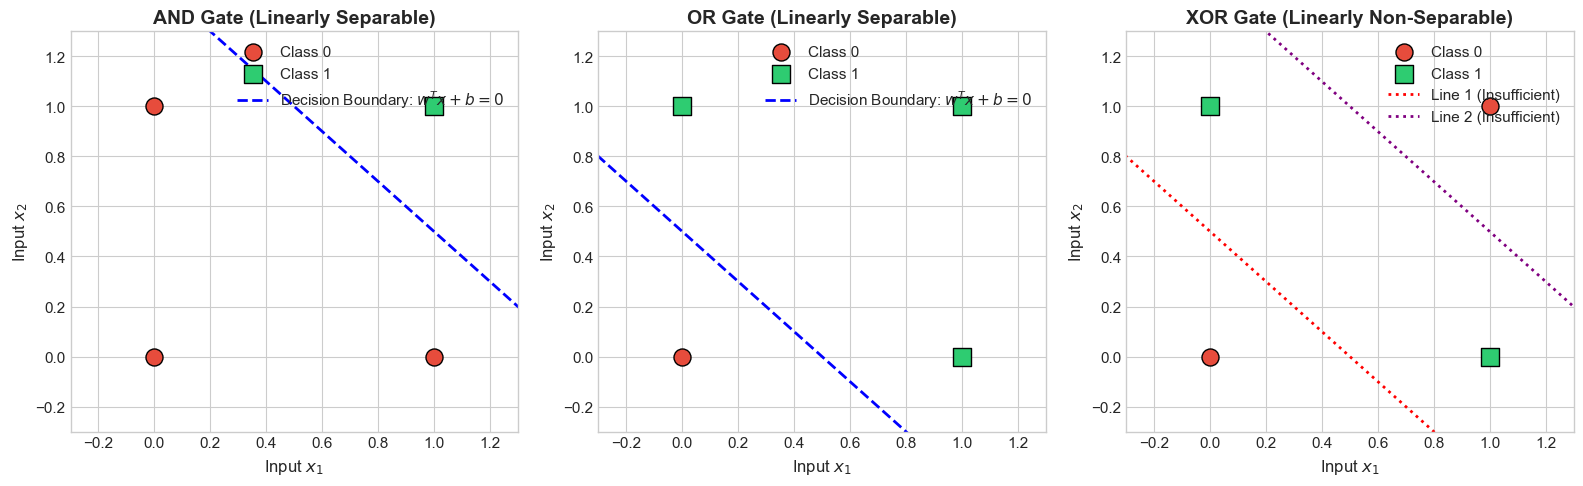

In [3]:
# Visualizing Linear Separability vs Non-Separability (AND vs OR vs XOR)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
titles = ["AND Gate (Linearly Separable)", "OR Gate (Linearly Separable)", "XOR Gate (Linearly Non-Separable)"]
targets = [y_and, y_or, y_xor]

# Grid for decision boundary
x_vals = np.linspace(-0.5, 1.5, 100)

for idx, (ax, title, y_t) in enumerate(zip(axes, titles, targets)):
    # Plot classes
    ax.scatter(X_logic[y_t == 0, 0], X_logic[y_t == 0, 1], color='#e74c3c', s=150, edgecolors='black', label='Class 0', zorder=5)
    ax.scatter(X_logic[y_t == 1, 0], X_logic[y_t == 1, 1], color='#2ecc71', s=150, marker='s', edgecolors='black', label='Class 1', zorder=5)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Input $x_1$')
    ax.set_ylabel('Input $x_2$')
    ax.set_xlim(-0.3, 1.3)
    ax.set_ylim(-0.3, 1.3)

    if idx == 0:
        # Decision boundary for AND: x1 + x2 = 1.5
        ax.plot(x_vals, 1.5 - x_vals, 'b--', linewidth=2, label='Decision Boundary: $w^Tx+b=0$')
    elif idx == 1:
        # Decision boundary for OR: x1 + x2 = 0.5
        ax.plot(x_vals, 0.5 - x_vals, 'b--', linewidth=2, label='Decision Boundary: $w^Tx+b=0$')
    else:
        # XOR requires TWO non-linear boundaries!
        ax.plot(x_vals, 0.5 - x_vals, 'r:', linewidth=2, label='Line 1 (Insufficient)')
        ax.plot(x_vals, 1.5 - x_vals, 'purple', linestyle=':', linewidth=2, label='Line 2 (Insufficient)')

    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


---
# 📘 Module 2: Architecture of Artificial Neural Networks (ANN / MLP)

### 2.1 From Perceptron to Multi-Layer Perceptrons (MLP)
To solve non-linearly separable problems like XOR, we assemble neurons into multiple layers:
1. **Input Layer**: Transmits feature vector $\mathbf{x} \in \mathbb{R}^d$ into the network without computation.
2. **Hidden Layer(s)**: Intermediate computational layers. Each hidden neuron acts as a feature detector, projecting the input into a transformed feature space where complex boundaries become linearly separable.
3. **Output Layer**: Computes the final predictions (probabilities for classification, continuous values for regression).

```
   [Input Layer]            [Hidden Layer]           [Output Layer]
     (d features)             (h neurons)              (c classes)
        ( x1 ) --------------> ( a1^(1) )
               \             /            \
                \           /              \
        ( x2 ) --------------> ( a2^(1) ) ------> ( y_hat )
                /           \              /
               /             \            /
        ( x3 ) --------------> ( a3^(1) )
```

### 2.2 Deep Dive: Anatomy of a Neuron & Why We Need Bias
Every neuron in a hidden layer performs two mathematical operations:
1. **Linear Combination (Affine Transformation)**:
   $$z = \sum_{i=1}^n w_i a_i^{[l-1]} + b = \mathbf{w}^T \mathbf{a}^{[l-1]} + b$$
2. **Non-linear Activation**:
   $$a = g(z)$$

**Why is Bias ($b$) essential?**
Without a bias term ($b = 0$), the linear hyperplane $\mathbf{w}^T \mathbf{x} = 0$ is strictly constrained to pass through the origin $(0, 0)$. The bias acts as a threshold shifter, allowing the boundary to translate anywhere in the feature space.

### 2.3 The Universal Approximation Theorem (Cybenko, 1989; Hornik, 1991)
* **Theorem**: A feedforward neural network with a single hidden layer containing a finite number of neurons can approximate any continuous function on compact subsets of $\mathbb{R}^n$ to arbitrary precision, provided the activation function is non-linear and continuous.
* **Why Deep over Shallow?** While a shallow wide network *can* theoretically approximate functions, it requires an exponential number of neurons. **Deep networks** (multiple hidden layers) achieve hierarchical abstraction with exponentially fewer parameters. Low layers learn simple primitives (edges, textures); higher layers compose them into complex semantics (shapes, objects).

### 2.4 Forward Propagation: Full Matrix Mathematics
Let $X \in \mathbb{R}^{N \times d}$ be a mini-batch of $N$ samples with $d$ features:

$$\mathbf{Z}^{[1]} = X \mathbf{W}^{[1]} + \mathbf{b}^{[1]} \quad [N \times h_1]$$
$$\mathbf{A}^{[1]} = g^{[1]}(\mathbf{Z}^{[1]}) \quad [N \times h_1]$$
$$\mathbf{Z}^{[2]} = \mathbf{A}^{[1]} \mathbf{W}^{[2]} + \mathbf{b}^{[2]} \quad [N \times h_2]$$
$$\mathbf{A}^{[2]} = g^{[2]}(\mathbf{Z}^{[2]}) \quad [N \times h_2]$$
$$\hat{Y} = \mathbf{A}^{[L]} = g^{[L]}(\mathbf{Z}^{[L]}) \quad [N \times c]$$

### 2.5 Backpropagation & The Chain Rule of Calculus
Backpropagation propagates the error gradient from the loss function backwards through each layer using the multivariate chain rule:

$$\delta^{[L]} = \frac{\partial \mathcal{L}}{\partial \mathbf{Z}^{[L]}} = \mathbf{A}^{[L]} - Y \quad (\text{for Softmax + Cross-Entropy / Sigmoid + BCE})$$
$$\frac{\partial \mathcal{L}}{\partial \mathbf{W}^{[l]}} = \frac{1}{N} (\mathbf{A}^{[l-1]})^T \delta^{[l]}$$
$$\frac{\partial \mathcal{L}}{\partial \mathbf{b}^{[l]}} = \frac{1}{N} \sum_{i=1}^N \delta_i^{[l]}$$
$$\delta^{[l-1]} = (\delta^{[l]} (\mathbf{W}^{[l]})^T) \odot (g^{[l-1]})'(\mathbf{Z}^{[l-1]})$$

Where $\odot$ represents the Hadamard (element-wise) product.


In [4]:
# 2.6 NumPy Implementation from Scratch: 2-Layer Neural Network Solving XOR
class TwoLayerNeuralNetwork:
    """
    A 2-Layer MLP (Input -> Hidden -> Output) built from scratch in pure NumPy.
    Architecture: 2 Inputs -> 4 Hidden Neurons (Tanh) -> 1 Output (Sigmoid).
    Demonstrates forward pass, exact backpropagation, and solving non-linear XOR!
    """
    def __init__(self, input_dim=2, hidden_dim=4, output_dim=1, lr=0.5):
        self.lr = lr
        # Xavier / He Initialization
        np.random.seed(SEED)
        self.W1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2.0 / input_dim)
        self.b1 = np.zeros((1, hidden_dim))
        self.W2 = np.random.randn(hidden_dim, output_dim) * np.sqrt(2.0 / hidden_dim)
        self.b2 = np.zeros((1, output_dim))
        self.loss_history = []

    def _tanh(self, z):
        return np.tanh(z)

    def _tanh_derivative(self, a):
        return 1.0 - a ** 2

    def _sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -25, 25)))

    def forward(self, X):
        # Layer 1: Affine + Tanh
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = self._tanh(self.Z1)
        # Layer 2: Affine + Sigmoid
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = self._sigmoid(self.Z2)
        return self.A2

    def backward(self, X, y):
        m = X.shape[0]
        # Output layer error: dL/dZ2 for BCE with Sigmoid simplifies cleanly to (A2 - y)
        dZ2 = self.A2 - y
        dW2 = (1.0 / m) * np.dot(self.A1.T, dZ2)
        db2 = (1.0 / m) * np.sum(dZ2, axis=0, keepdims=True)

        # Hidden layer error via chain rule: dZ1 = (dZ2 * W2^T) * tanh'(A1)
        dA1 = np.dot(dZ2, self.W2.T)
        dZ1 = dA1 * self._tanh_derivative(self.A1)
        dW1 = (1.0 / m) * np.dot(X.T, dZ1)
        db1 = (1.0 / m) * np.sum(dZ1, axis=0, keepdims=True)

        # Gradient Descent parameter update
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1

    def fit(self, X, y, epochs=2000):
        y = y.reshape(-1, 1)
        for epoch in range(epochs):
            A2 = self.forward(X)
            # Binary Cross-Entropy Loss
            loss = -np.mean(y * np.log(A2 + 1e-12) + (1 - y) * np.log(1 - A2 + 1e-12))
            self.loss_history.append(loss)
            self.backward(X, y)
        return self

    def predict(self, X):
        probs = self.forward(X)
        return (probs >= 0.5).astype(int)

# Train our 2-layer Neural Network on XOR!
nn_xor = TwoLayerNeuralNetwork(input_dim=2, hidden_dim=4, output_dim=1, lr=0.5)
nn_xor.fit(X_logic, y_xor, epochs=2500)

preds = nn_xor.predict(X_logic).flatten()
probs = nn_xor.forward(X_logic).flatten()
print("=" * 55)
print("ANN XOR TRAINING RESULTS (SOLVING THE IMPOSSIBLE)")
print("=" * 55)
for i in range(len(X_logic)):
    print(f"Input: {X_logic[i]} | True: {y_xor[i]} | Prob: {probs[i]:.4f} | Pred: {preds[i]}")
print(f"Final Binary Cross-Entropy Loss: {nn_xor.loss_history[-1]:.6f}")
print("SUCCESS: Multi-layer Neural Network conquered the XOR problem!")


ANN XOR TRAINING RESULTS (SOLVING THE IMPOSSIBLE)
Input: [0 0] | True: 0 | Prob: 0.0002 | Pred: 0
Input: [0 1] | True: 1 | Prob: 0.9978 | Pred: 1
Input: [1 0] | True: 1 | Prob: 0.9978 | Pred: 1
Input: [1 1] | True: 0 | Prob: 0.0033 | Pred: 0
Final Binary Cross-Entropy Loss: 0.001990
SUCCESS: Multi-layer Neural Network conquered the XOR problem!


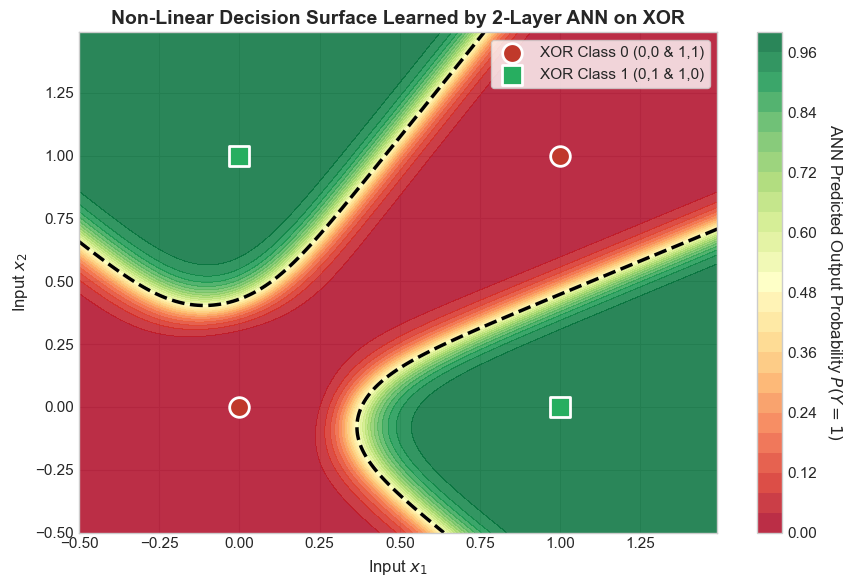

In [5]:
# Visualizing the Non-Linear Decision Boundary Learned by the 2-Layer Neural Network on XOR
h = 0.01
x_min, x_max = -0.5, 1.5
y_min, y_max = -0.5, 1.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
grid_points = np.c_[xx.ravel(), yy.ravel()]

# Predict probabilities over the continuous grid
Z_grid = nn_xor.forward(grid_points).reshape(xx.shape)

plt.figure(figsize=(9, 6))
contour = plt.contourf(xx, yy, Z_grid, levels=30, cmap='RdYlGn', alpha=0.85)
cbar = plt.colorbar(contour)
cbar.set_label('ANN Predicted Output Probability $P(Y=1)$', rotation=270, labelpad=20)

# Plot decision boundary threshold at 0.5
plt.contour(xx, yy, Z_grid, levels=[0.5], colors='black', linewidths=2.5, linestyles='--')

# Plot true XOR points
plt.scatter(X_logic[y_xor == 0, 0], X_logic[y_xor == 0, 1], color='#c0392b', s=200, edgecolors='white', linewidth=2, label='XOR Class 0 (0,0 & 1,1)')
plt.scatter(X_logic[y_xor == 1, 0], X_logic[y_xor == 1, 1], color='#27ae60', s=200, marker='s', edgecolors='white', linewidth=2, label='XOR Class 1 (0,1 & 1,0)')

plt.title('Non-Linear Decision Surface Learned by 2-Layer ANN on XOR', fontweight='bold', fontsize=14)
plt.xlabel('Input $x_1$')
plt.ylabel('Input $x_2$')
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()


---
# 📘 Module 3: The Complete Encyclopedia of Activation Functions

### 3.1 Why Non-Linear Activation Functions are Mathematically Mandatory
Suppose every layer in a neural network only performed a linear transformation $g(z) = z$.
For a 3-layer network:
$$\mathbf{a}^{[1]} = \mathbf{W}_1 \mathbf{x} + \mathbf{b}_1$$
$$\mathbf{a}^{[2]} = \mathbf{W}_2 \mathbf{a}^{[1]} + \mathbf{b}_2 = \mathbf{W}_2 (\mathbf{W}_1 \mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2 = (\mathbf{W}_2 \mathbf{W}_1) \mathbf{x} + (\mathbf{W}_2 \mathbf{b}_1 + \mathbf{b}_2)$$
$$\hat{\mathbf{y}} = \mathbf{W}_3 \mathbf{a}^{[2]} + \mathbf{b}_3 = (\mathbf{W}_3 \mathbf{W}_2 \mathbf{W}_1) \mathbf{x} + \mathbf{b}_{\text{effective}} = \mathbf{W}_{\text{effective}} \mathbf{x} + \mathbf{b}_{\text{effective}}$$

**The Mathematical Proof**: The composition of arbitrary linear transformations is strictly linear. No matter how many layers or neurons a network contains, **without non-linear activations, a 100-layer deep network collapses into a single-layer linear regression model!** Non-linearity is what allows networks to carve arbitrary complex manifolds and decision boundaries.

---

### 3.2 Deep Dive into Every Major Activation Function

#### 1. Heaviside Step Function
* **Formula**: $f(z) = 1 \text{ if } z \ge 0 \text{ else } 0$
* **Derivative**: $f'(z) = 0$ for all $z \ne 0$; undefined at $z = 0$.
* **Analysis**: Historically used in Rosenblatt's Perceptron. **Useless for deep learning** because the gradient is zero everywhere, which completely halts gradient descent ($\Delta w = -\eta \cdot 0 = 0$).

#### 2. Sigmoid (Logistic) Function
* **Formula**: $\sigma(z) = \frac{1}{1 + e^{-z}}$
* **Derivative**: $\sigma'(z) = \sigma(z)(1 - \sigma(z))$
* **Range**: $(0, 1)$
* **Pros**: Smooth, differentiable, natural probabilistic interpretation.
* **Fatal Flaws**:
  1. **Vanishing Gradient**: For $|z| > 4$, the derivative $\sigma'(z) \approx 0$. Its maximum derivative is only $0.25$ at $z=0$. In a 5-layer network, multiplying derivatives $(0.25)^5 \approx 0.00097$ causes gradients to vanish, preventing early layers from learning.
  2. **Not Zero-Centered**: Because outputs are always positive ($>0$), gradients on weights during backpropagation all share the same sign, forcing sub-optimal "zig-zag" parameter updates.
* **Best Practice**: Used **only in the output layer for binary classification**. Avoid in hidden layers.

#### 3. Hyperbolic Tangent (Tanh) Function
* **Formula**: $\tanh(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}} = 2\sigma(2z) - 1$
* **Derivative**: $\tanh'(z) = 1 - \tanh^2(z)$
* **Range**: $(-1, 1)$
* **Pros**: **Zero-centered** (mean output close to 0), converges faster than Sigmoid. Maximum derivative is $1.0$ at $z=0$.
* **Cons**: Still suffers from vanishing gradients when saturated ($|z| > 3$).
* **Best Practice**: Great for recurrent architectures (RNN / LSTM cell states) and shallow neural networks.

#### 4. Rectified Linear Unit (ReLU)
* **Formula**: $f(z) = \max(0, z)$
* **Derivative**: $f'(z) = 1 \text{ if } z > 0 \text{ else } 0$
* **Range**: $[0, \infty)$
* **Pros**:
  1. **Solves Vanishing Gradients**: Gradient is a constant $1.0$ for all positive inputs.
  2. **Computational Speed**: Requires only a simple threshold check (no expensive $\exp$ or division).
  3. **Sparse Representation**: Naturally sets negative activations to 0, inducing sparsity.
* **The Fatal Flaw: The Dying ReLU Problem**:
  If a large gradient updates weights such that a neuron outputs $z < 0$ across all training points, its gradient is permanently $0$. The neuron becomes inactive ("dead") and never recovers.
* **Best Practice**: The default starting point for hidden layers in deep vision and tabular networks.

#### 5. Leaky ReLU & Parametric ReLU (PReLU)
* **Formula**: $f(z) = \max(\alpha z, z)$ where $\alpha \approx 0.01$ (fixed in Leaky ReLU; learnable parameter in PReLU).
* **Derivative**: $f'(z) = 1 \text{ if } z > 0 \text{ else } \alpha$
* **Range**: $(-\infty, \infty)$
* **Pros**: Directly solves the "Dying ReLU" flaw by ensuring a small non-zero gradient ($\alpha$) persists for $z < 0$.

#### 6. Exponential Linear Unit (ELU)
* **Formula**: $f(z) = z \text{ if } z > 0 \text{ else } \alpha(e^z - 1)$
* **Pros**: Smooth everywhere, brings mean activation closer to zero, robust to noise.
* **Cons**: Slower due to $\exp(z)$ computation.

#### 7. Softmax Function
* **Formula**: $\text{Softmax}(z)_i = \frac{e^{z_i}}{\sum_{j=1}^K e^{z_j}}$
* **Range**: $(0, 1)$, with $\sum_{i=1}^K \text{Softmax}(z)_i = 1.0$
* **Best Practice**: **Mandatory output activation for mutually exclusive multi-class classification**.

#### 8. Modern Activations: Swish (SiLU) & GELU
* **Swish (Google Brain)**: $f(z) = z \cdot \sigma(z)$. Outperforms ReLU on deep vision networks (EfficientNet).
* **GELU (Gaussian Error Linear Unit)**: $f(z) = z \cdot \Phi(z)$. The modern standard used across state-of-the-art Transformers (BERT, GPT-3/4, LLaMA).


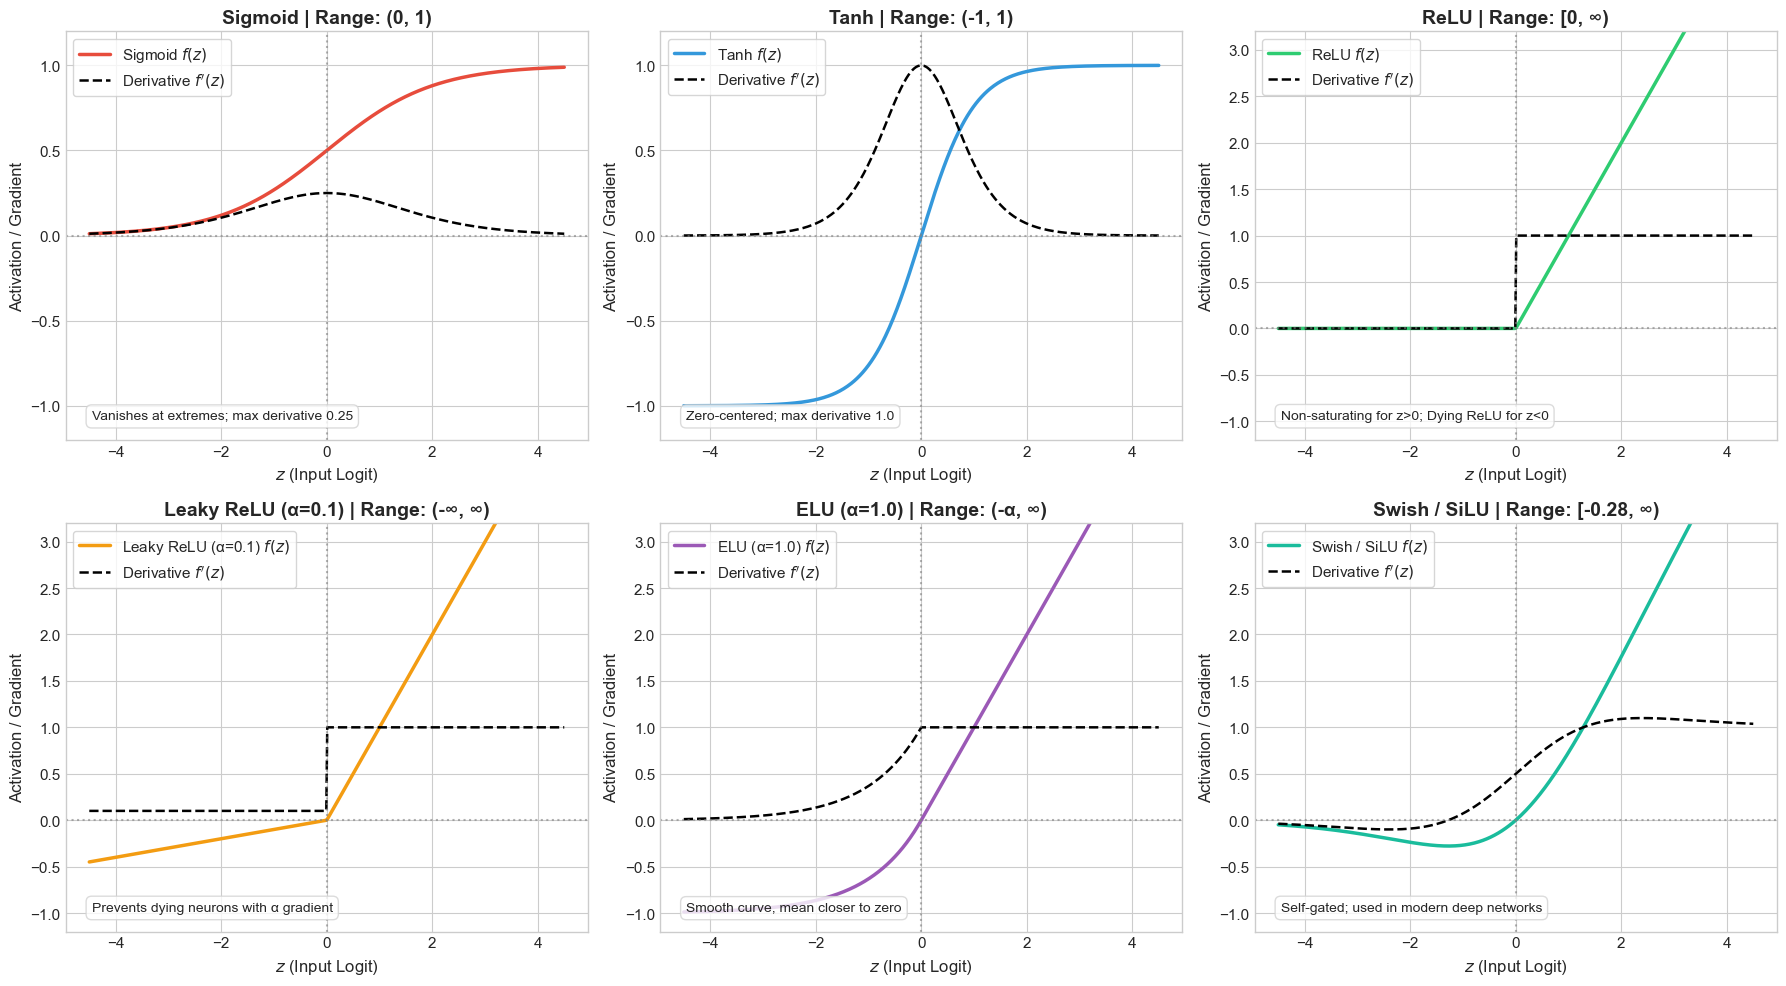

In [6]:
# 3.3 Visual Comparison Dashboard: Activations & Their Mathematical Derivatives
z = np.linspace(-4.5, 4.5, 500)

# Define functions and exact derivatives
def sigmoid(x): return 1.0 / (1.0 + np.exp(-x))
def d_sigmoid(x): s = sigmoid(x); return s * (1.0 - s)

def tanh(x): return np.tanh(x)
def d_tanh(x): return 1.0 - np.tanh(x)**2

def relu(x): return np.maximum(0, x)
def d_relu(x): return np.where(x > 0, 1.0, 0.0)

def leaky_relu(x, alpha=0.1): return np.where(x > 0, x, alpha * x)
def d_leaky_relu(x, alpha=0.1): return np.where(x > 0, 1.0, alpha)

def elu(x, alpha=1.0): return np.where(x > 0, x, alpha * (np.exp(x) - 1.0))
def d_elu(x, alpha=1.0): return np.where(x > 0, 1.0, elu(x, alpha) + alpha)

def swish(x): return x * sigmoid(x)
def d_swish(x): s = sigmoid(x); return s + x * s * (1.0 - s)

def gelu(x): return 0.5 * x * (1.0 + np.tanh(np.sqrt(2.0 / np.pi) * (x + 0.044715 * x**3)))

# Plotting 8-Panel Comprehensive Figure
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

act_data = [
    ("Sigmoid", sigmoid(z), d_sigmoid(z), "#e74c3c", "(0, 1)", "Vanishes at extremes; max derivative 0.25"),
    ("Tanh", tanh(z), d_tanh(z), "#3498db", "(-1, 1)", "Zero-centered; max derivative 1.0"),
    ("ReLU", relu(z), d_relu(z), "#2ecc71", "[0, ∞)", "Non-saturating for z>0; Dying ReLU for z<0"),
    ("Leaky ReLU (α=0.1)", leaky_relu(z), d_leaky_relu(z), "#f39c12", "(-∞, ∞)", "Prevents dying neurons with α gradient"),
    ("ELU (α=1.0)", elu(z), d_elu(z), "#9b59b6", "(-α, ∞)", "Smooth curve, mean closer to zero"),
    ("Swish / SiLU", swish(z), d_swish(z), "#1abc9c", "[-0.28, ∞)", "Self-gated; used in modern deep networks")
]

for idx, (name, val, d_val, color, rng, note) in enumerate(act_data):
    ax = axes[idx]
    ax.plot(z, val, label=f'{name} $f(z)$', color=color, linewidth=2.5)
    ax.plot(z, d_val, label=f"Derivative $f'(z)$", color='black', linestyle='--', linewidth=1.8)
    ax.axhline(0, color='gray', linestyle=':', alpha=0.6)
    ax.axvline(0, color='gray', linestyle=':', alpha=0.6)
    ax.set_title(f"{name} | Range: {rng}", fontweight='bold')
    ax.set_xlabel('$z$ (Input Logit)')
    ax.set_ylabel('Activation / Gradient')
    ax.legend(loc='upper left', frameon=True)
    ax.text(0.05, 0.05, note, transform=ax.transAxes, fontsize=10,
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8, edgecolor='lightgray'))
    ax.set_ylim(-1.2, 3.2 if 'ReLU' in name or 'Swish' in name or 'ELU' in name else 1.2)

plt.tight_layout()
plt.show()


### 3.5 Activation Function Selection Matrix
Use this reference guide when architecting neural networks:

| Activation Function | Formula | Range | Where to Use? | Key Advantages | Major Limitations |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Sigmoid** | $\frac{1}{1+e^{-z}}$ | $(0, 1)$ | Output layer for **Binary Classification** | Probabilistic output | Vanishing gradients; not zero-centered |
| **Softmax** | $\frac{e^{z_i}}{\sum e^{z_j}}$ | $(0, 1)$ | Output layer for **Multi-Class Classification** | True probability distribution | Sensitive to outliers |
| **Linear** | $f(z) = z$ | $(-\infty, \infty)$ | Output layer for **Regression** | Unconstrained values | Cannot be used in hidden layers |
| **ReLU** | $\max(0, z)$ | $[0, \infty)$ | **Default choice for hidden layers** | Blazing fast; non-saturating | "Dying ReLU" problem |
| **Leaky ReLU** | $\max(\alpha z, z)$ | $(-\infty, \infty)$ | Hidden layers if Dying ReLU observed | Never dies | Extra hyperparameter $\alpha$ |
| **ELU** | $z \text{ or } \alpha(e^z-1)$ | $(-\alpha, \infty)$ | Hidden layers requiring smooth gradients | Mean close to 0 | Exponentially heavier compute |
| **GELU / Swish** | $z \cdot \Phi(z)$ | $[-0.28, \infty)$ | **Modern Transformers & LLMs** | Superior empirical convergence | Non-trivial computation |


---
# 📘 Module 4: Loss Functions (Cost Functions) in Deep Learning

### 4.1 Fundamental Definitions
* **Loss Function $\mathcal{L}(y^{(i)}, \hat{y}^{(i)})$**: Quantifies the penalty for a single training sample.
* **Cost Function $J(\mathbf{W}, \mathbf{b})$**: The empirical average loss computed across the entire training dataset:
  $$J(\mathbf{W}, \mathbf{b}) = \frac{1}{N} \sum_{i=1}^{N} \mathcal{L}(y^{(i)}, \hat{y}^{(i)})$$
* **Evaluation Metric**: Non-differentiable human-interpretable measures (e.g., Accuracy, F1-Score, ROC-AUC) used to judge performance.

---

### 4.2 Regression Loss Functions

#### 1. Mean Squared Error (MSE / L2 Loss)
$$J_{\text{MSE}} = \frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2$$
* **Derivative**: $\frac{\partial J}{\partial \hat{y}_i} = -\frac{2}{N}(y_i - \hat{y}_i)$
* **Properties**: Quadradically penalizes large errors. Sensitive to outliers. Smooth and easy to optimize via gradient descent.

#### 2. Mean Absolute Error (MAE / L1 Loss)
$$J_{\text{MAE}} = \frac{1}{N} \sum_{i=1}^N |y_i - \hat{y}_i|$$
* **Derivative**: $\frac{\partial J}{\partial \hat{y}_i} = -\frac{1}{N} \text{sign}(y_i - \hat{y}_i)$
* **Properties**: Highly robust to outliers. However, its gradient has constant magnitude and is non-differentiable at $y = \hat{y}$, requiring sub-gradient methods.

#### 3. Huber Loss (Smooth L1 Loss)
Combines the smooth convergence of MSE near zero with the outlier-robustness of MAE far from zero:
$$L_\delta(y, \hat{y}) = \begin{cases} \frac{1}{2}(y - \hat{y})^2 & \text{for } |y - \hat{y}| \le \delta \\ \delta |y - \hat{y}| - \frac{1}{2}\delta^2 & \text{otherwise} \end{cases}$$

---

### 4.3 Classification Loss Functions

#### 1. Binary Cross-Entropy (Log Loss)
For binary classification where $y \in \{0, 1\}$ and $\hat{y} = P(Y=1|\mathbf{x}) = \sigma(z)$:
$$\mathcal{L}_{\text{BCE}}(y, \hat{y}) = -\left[ y \ln(\hat{y}) + (1 - y) \ln(1 - \hat{y}) \right]$$

**Information-Theoretic Derivation**:
Binary Cross-Entropy measures the **Kullback-Leibler (KL) divergence** plus Shannon entropy between the true distribution $p$ and predicted model distribution $q$:
$$H(p, q) = -\sum_{x} p(x) \log q(x)$$

**Why NOT use MSE for classification with Sigmoid?**
If we plug $\hat{y} = \sigma(z)$ into MSE $(y - \sigma(z))^2$, the loss surface becomes **highly non-convex with numerous flat plateaus and local minima**. In contrast, Binary Cross-Entropy paired with Sigmoid cancels the derivative of the sigmoid ($\sigma'(z)$), yielding an elegant, strictly convex gradient:
$$\frac{\partial \mathcal{L}_{\text{BCE}}}{\partial z} = \hat{y} - y$$
This guarantees that large errors yield large gradients, preventing training stagnation!

#### 2. Categorical Cross-Entropy (CCE)
For multi-class classification with $C$ mutually exclusive classes and one-hot encoded targets:
$$\mathcal{L}_{\text{CCE}}(y, \hat{y}) = -\sum_{c=1}^C y_c \ln(\hat{y}_c)$$

#### 3. Sparse Categorical Cross-Entropy (SCCE)
Mathematically identical to Categorical Cross-Entropy, but accepts target labels as raw integers (e.g., $y \in \{0, 1, 2, \dots\}$) rather than one-hot vectors. This eliminates massive memory overhead when dealing with thousands of classes (e.g., NLP token vocabularies).


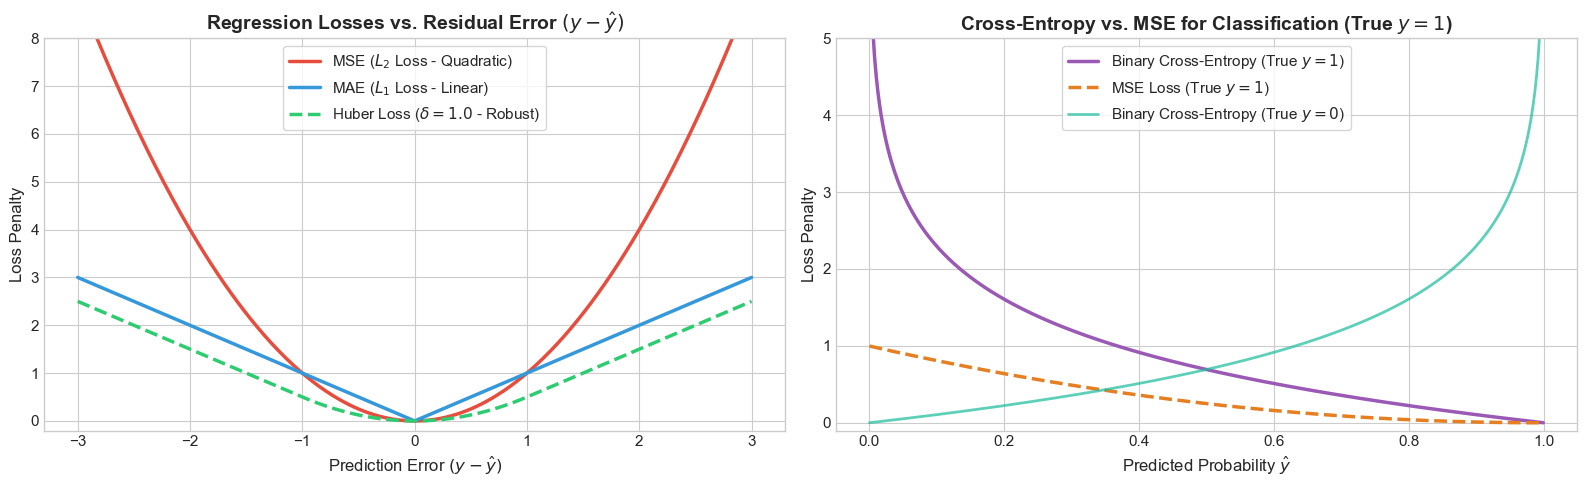

In [7]:
# 4.4 Visualizing Regression & Classification Loss Penalties
errors = np.linspace(-3, 3, 400)

# Regression losses
mse_loss = errors ** 2
mae_loss = np.abs(errors)
delta = 1.0
huber_loss = np.where(np.abs(errors) <= delta, 0.5 * errors**2, delta * np.abs(errors) - 0.5 * delta**2)

# Classification BCE loss for True Label y=1 as predicted probability p varies from 0 to 1
p = np.linspace(0.001, 0.999, 400)
bce_when_y1 = -np.log(p)
bce_when_y0 = -np.log(1.0 - p)
mse_when_y1 = (1.0 - p)**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Regression Loss Comparison
ax1.plot(errors, mse_loss, label='MSE ($L_2$ Loss - Quadratic)', color='#e74c3c', linewidth=2.5)
ax1.plot(errors, mae_loss, label='MAE ($L_1$ Loss - Linear)', color='#3498db', linewidth=2.5)
ax1.plot(errors, huber_loss, label='Huber Loss ($\delta=1.0$ - Robust)', color='#2ecc71', linestyle='--', linewidth=2.5)
ax1.set_title('Regression Losses vs. Residual Error $(y - \hat{y})$', fontweight='bold')
ax1.set_xlabel('Prediction Error $(y - \hat{y})$')
ax1.set_ylabel('Loss Penalty')
ax1.set_ylim(-0.2, 8)
ax1.legend(frameon=True)

# Classification Loss Comparison
ax2.plot(p, bce_when_y1, label='Binary Cross-Entropy (True $y=1$)', color='#9b59b6', linewidth=2.5)
ax2.plot(p, mse_when_y1, label='MSE Loss (True $y=1$)', color='#e67e22', linestyle='--', linewidth=2.5)
ax2.plot(p, bce_when_y0, label='Binary Cross-Entropy (True $y=0$)', color='#1abc9c', linewidth=2.0, alpha=0.7)
ax2.set_title('Cross-Entropy vs. MSE for Classification (True $y=1$)', fontweight='bold')
ax2.set_xlabel('Predicted Probability $\hat{y}$')
ax2.set_ylabel('Loss Penalty')
ax2.set_ylim(-0.1, 5)
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()


---
# 📘 Module 5: The Optimization Landscape — Algorithms & Dynamics

### 5.1 The Optimization Problem in Deep Learning
Optimization in deep neural networks is fundamentally non-convex. The loss surface features:
1. **Local Minima & Plateaus**: Vast flat regions where gradients shrink close to zero.
2. **Saddle Points**: Points where the gradient is zero, but the surface slopes down along some directions and up along others. High-dimensional loss landscapes are dominated by saddle points rather than local minima.
3. **Ravines (Pathological Curvature)**: Surfaces that curve much more steeply in one direction than another, causing vanilla gradient descent to oscillate wildly back and forth.

---

### 5.2 The Gradient Descent Spectrum

#### 1. Batch Gradient Descent (BGD)
* Computes gradients across the **entire dataset** ($N$ samples) per step:
  $$\theta \leftarrow \theta - \eta \nabla_\theta J(\theta)$$
* **Pros**: Deterministic gradient, smooth convergence.
* **Cons**: Intolerably slow on large datasets; cannot fit into GPU memory; easily gets stuck in saddle points.

#### 2. Stochastic Gradient Descent (SGD)
* Computes gradients for **a single random sample** ($i$) per step:
  $$\theta \leftarrow \theta - \eta \nabla_\theta \mathcal{L}_i(\theta)$$
* **Pros**: Blazing fast per update; noise allows parameters to escape shallow local minima and saddle points.
* **Cons**: Violent oscillations; never settles smoothly at the true minimum without a decaying learning rate.

#### 3. Mini-Batch Gradient Descent (The Gold Standard)
* Computes gradients over a small batch of $B \in \{32, 64, 128, 256\}$ samples.
* Combines the computational vectorization of GPUs with the regularizing noise of SGD.

---

### 5.3 Advanced Momentum & Adaptive Optimizers

#### 1. SGD with Momentum
* **Intuition**: A heavy bowling ball rolling down a bumpy hill accumulates velocity, blowing through small bumps and resisting perpendicular oscillations.
* **Update Equations**:
  $$v_t = \beta \cdot v_{t-1} + (1 - \beta) \cdot g_t$$
  $$\theta_t = \theta_{t-1} - \eta \cdot v_t$$
* Where $\beta \approx 0.9$ is the momentum coefficient. It averages past gradients via an **Exponential Moving Average (EMA)**.

#### 2. Nesterov Accelerated Gradient (NAG)
* Rather than evaluating the gradient at the current position, NAG evaluates the gradient at a **look-ahead position** $(\theta_{t-1} - \beta v_{t-1})$. This provides an anticipatory "braking" mechanism that prevents overshooting narrow minima.

#### 3. AdaGrad (Adaptive Gradient)
* Adapts the learning rate individually for each parameter based on historical gradients. Frequently updated parameters get smaller steps; rare features get larger steps:
  $$G_t = G_{t-1} + g_t^2 \quad \text{(Accumulated squared gradients)}$$
  $$\theta_t = \theta_{t-1} - \frac{\eta}{\sqrt{G_t + \epsilon}} \cdot g_t$$
* **The Fatal Flaw**: Because $g_t^2 \ge 0$, $G_t$ monotonically increases. The effective learning rate eventually decays to 0, completely freezing training early!

#### 4. RMSprop (Hinton, 2012)
* Solves AdaGrad's premature freeze by replacing the monotonic sum with an **Exponential Moving Average (EMA)** of squared gradients:
  $$S_t = \beta \cdot S_{t-1} + (1 - \beta) \cdot g_t^2$$
  $$\theta_t = \theta_{t-1} - \frac{\eta}{\sqrt{S_t + \epsilon}} \cdot g_t$$
* Here, $\beta \approx 0.9$. RMSprop smoothly scales updates by the root mean square of recent gradients, allowing indefinite learning.

#### 5. Adam (Adaptive Moment Estimation - Kingma & Ba, 2014)
* **The Industry Gold Standard**: Combines the best of **Momentum** (first moment $m_t$) and **RMSprop** (second moment $v_t$), with **bias correction** to compensate for zero-initialization in early iterations.
* **Update Equations**:
  $$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t \quad \text{(1st Moment: Mean)}$$
  $$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2 \quad \text{(2nd Moment: Uncentered Variance)}$$
  $$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \quad \hat{v}_t = \frac{v_t}{1 - \beta_2^t} \quad \text{(Bias Corrections)}$$
  $$\theta_t = \theta_{t-1} - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$
* **Default Hyperparameters**: $\eta = 0.001$, $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$.

#### 6. AdamW (Loshchilov & Hutter, 2017)
* Fixes a subtle flaw in Adam's interaction with $L_2$ regularization. Standard Adam mixes weight decay into the gradient, leading to scaled-down decay for parameters with large historical gradients. **AdamW decouples weight decay directly from gradient updates**, achieving superior generalization across Vision Transformers and Large Language Models.


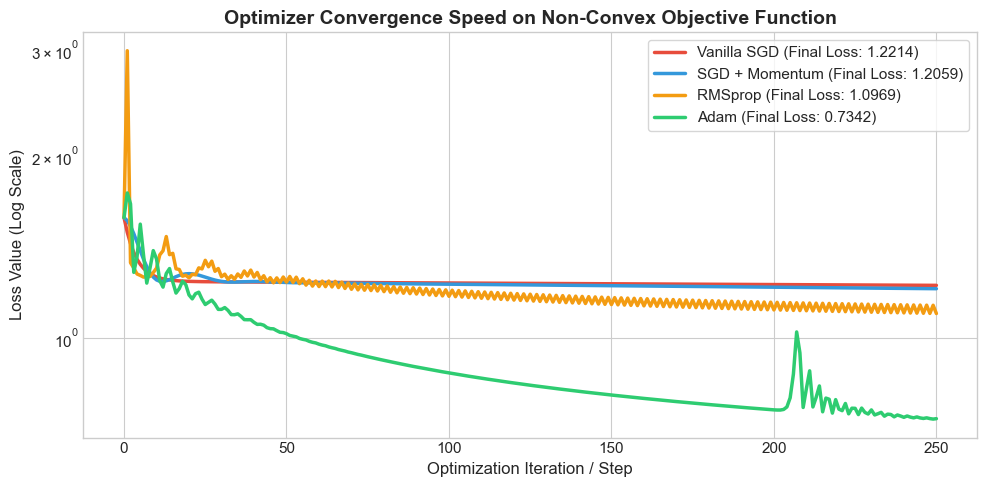

In [8]:
# 5.4 Hands-On Optimizer Shootout: Comparing Optimizer Dynamics on a Challenging Loss Surface
# Objective: Minimize Beale's non-convex test function f(x, y) = (1.5 - x + xy)^2 + (2.25 - x + xy^2)^2 + (2.625 - x + xy^3)^2
def beale(x, y):
    return (1.5 - x + x*y)**2 + (2.25 - x + x*y**2)**2 + (2.625 - x + x*y**3)**2

def grad_beale(x, y):
    # Analytical partial derivatives
    df_dx = (2 * (1.5 - x + x*y) * (-1 + y) +
             2 * (2.25 - x + x*y**2) * (-1 + y**2) +
             2 * (2.625 - x + x*y**3) * (-1 + y**3))
    df_dy = (2 * (1.5 - x + x*y) * x +
             2 * (2.25 - x + x*y**2) * (2*x*y) +
             2 * (2.625 - x + x*y**3) * (3*x*y**2))
    return np.array([df_dx, df_dy])

# Implement optimizers in pure NumPy to observe trajectory
def optimize_surface(optimizer_name, lr=0.01, epochs=300, start=(-2.0, -2.0)):
    pos = np.array(start, dtype=float)
    trajectory = [pos.copy()]
    losses = [beale(pos[0], pos[1])]

    v = np.zeros(2)
    s = np.zeros(2)
    beta1 = 0.9
    beta2 = 0.999
    eps = 1e-8

    for t in range(1, epochs + 1):
        g = grad_beale(pos[0], pos[1])
        # Clip gradient to prevent explosions in extreme ravines
        g = np.clip(g, -50, 50)

        if optimizer_name == 'Vanilla SGD':
            pos -= lr * g
        elif optimizer_name == 'SGD + Momentum':
            v = beta1 * v + (1 - beta1) * g
            pos -= lr * v
        elif optimizer_name == 'RMSprop':
            s = beta1 * s + (1 - beta1) * (g ** 2)
            pos -= (lr / (np.sqrt(s) + eps)) * g
        elif optimizer_name == 'Adam':
            v = beta1 * v + (1 - beta1) * g
            s = beta2 * s + (1 - beta2) * (g ** 2)
            v_hat = v / (1 - beta1 ** t)
            s_hat = s / (1 - beta2 ** t)
            pos -= (lr / (np.sqrt(s_hat) + eps)) * v_hat

        trajectory.append(pos.copy())
        losses.append(beale(pos[0], pos[1]))

    return np.array(trajectory), losses

opt_configs = [
    ('Vanilla SGD', 0.0005, '#e74c3c'),
    ('SGD + Momentum', 0.001, '#3498db'),
    ('RMSprop', 0.05, '#f39c12'),
    ('Adam', 0.1, '#2ecc71')
]

results = {}
for name, lr, color in opt_configs:
    traj, loss = optimize_surface(name, lr=lr, epochs=250, start=(-1.5, 1.5))
    results[name] = (traj, loss, color)

# Plotting Convergence Curves
plt.figure(figsize=(10, 5))
for name, (traj, loss, color) in results.items():
    plt.plot(loss, label=f"{name} (Final Loss: {loss[-1]:.4f})", color=color, linewidth=2.5)

plt.yscale('log')
plt.title('Optimizer Convergence Speed on Non-Convex Objective Function', fontweight='bold')
plt.xlabel('Optimization Iteration / Step')
plt.ylabel('Loss Value (Log Scale)')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


---
# 📘 Module 6: Neural Network Regularization & Training Stabilizers

### 6.1 The Overfitting Dilemma in Deep Networks
Deep Neural Networks possess millions of parameters, granting them staggering expressive capacity. Without regularization, they readily **memorize training noise** rather than learning generalizable patterns.

### 6.2 Key Regularization Techniques
1. **$L_1$ and $L_2$ Weight Regularization (Weight Decay)**:
   - Adds a penalty term to the cost function:
     $$J_{\text{reg}} = J_0 + \frac{\lambda}{2N} \sum \|\mathbf{W}\|^2$$
   - Penalizes large weights, driving irrelevant feature weights toward zero and encouraging smoother decision surfaces.
2. **Dropout (Srivastava et al., 2014)**:
   - During each forward pass in training, randomly deactivates each neuron with probability $p$ (e.g., $p = 0.2$ to $0.5$).
   - Prevents **feature co-adaptation** (no neuron can rely on a specific neighbor).
   - Equivalent to training an implicit ensemble of $2^N$ thinned subnetworks!
   - At test time, all neurons are active, but scaled (or training uses *inverted dropout* by dividing by $1 - p$).
3. **Batch Normalization (Ioffe & Szegedy, 2015)**:
   - Normalizes the activations of each layer across the current mini-batch:
     $$\mu_B = \frac{1}{m}\sum x_i, \quad \sigma_B^2 = \frac{1}{m}\sum (x_i - \mu_B)^2$$
     $$\hat{x}_i = \frac{x_i - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}, \quad y_i = \gamma \hat{x}_i + \beta$$
   - **Why is BatchNorm Revolutionary?**
     1. Mitigates **internal covariate shift** (stabilizes layer input distributions).
     2. Enables **substantially higher learning rates** for 5-10x faster convergence.
     3. Acts as an implicit regularizer, often reducing the need for heavy dropout.

### 6.3 Dynamic Training Callbacks
* **Early Stopping**: Monitors validation loss and halts training once it ceases to improve for a set number of epochs (`patience`), automatically restoring the best model weights.
* **ReduceLROnPlateau**: Dynamically cuts the learning rate by a factor (e.g., $\times 0.2$) when validation loss plateaus, enabling the optimizer to settle into fine minima.


---
# 📘 Module 7: Comprehensive Industry Hands-On Project
## 🏦 Bank Customer Churn Prediction & Retention System

### 7.1 Business Objective
Customer retention is the primary profit driver in retail banking: acquiring a new customer costs **5x more** than retaining an existing one.
Our objective is to engineer an **end-to-end Deep Artificial Neural Network** that predicts the probability of a customer closing their account (`Exited = 1`), enabling relationship managers to deploy targeted retention offers before the customer leaves.

```
+-------------------------------------------------------------------------------------------------+
|                                 END-TO-END DEEP LEARNING PIPELINE                                |
+-------------------------------------------------------------------------------------------------+
|  1. Ingestion: Bank_Customer_Churn.csv (10,000 customers, 13 features)                          |
|  2. EDA: Audit imbalance (~14-20% churn), feature distributions, age/balance correlations        |
|  3. Preprocessing: Drop IDs, OneHotEncode Geography, Encode Gender, Stratified 70/15/15 Split   |
|  4. Leakage-Free Scaling: StandardScaler fitted strictly on training partition                  |
|  5. Baseline ML: Logistic Regression & Random Forest benchmarks                                  |
|  6. Deep ANN Architecture: Input(11) -> Dense(64, ReLU) + BatchNorm + Dropout(0.3)             |
|                                       -> Dense(32, ReLU) + BatchNorm + Dropout(0.2)             |
|                                       -> Dense(16, ReLU) + Dropout(0.1)                          |
|                                       -> Dense(1, Sigmoid)                                      |
|  7. Optimizer Shootout: Side-by-side empirical comparison (SGD vs RMSprop vs Adam)              |
|  8. Evaluation Suite: Confusion Matrix, Classification Report, ROC-AUC, PR-AUC Curves           |
|  9. Decision Threshold Optimization: Maximizing recall on churners                              |
| 10. Production Inference API: Automated risk tiering & proactive retention strategy generator |
+-------------------------------------------------------------------------------------------------+
```


In [9]:
# 7.2 Dataset Ingestion & Exploratory Data Analysis (EDA)
# Load Bank_Customer_Churn dataset (checking local directories)
dataset_candidates = [
    'Bank_Customer_Churn.csv',
    '../data/Bank_Customer_Churn.csv',
    'data/Bank_Customer_Churn.csv',
    'Deep_learning_video/Bank_Customer_Churn.csv'
]

churn_df = None
for path in dataset_candidates:
    if os.path.exists(path):
        churn_df = pd.read_csv(path)
        print(f"Loaded dataset from: {path}")
        break

if churn_df is None:
    raise FileNotFoundError("Bank_Customer_Churn.csv could not be found.")

print(f"Dataset Dimensions: {churn_df.shape[0]:,} rows, {churn_df.shape[1]} columns")
print("\nDataset Head:")
display(churn_df.head(4)) if 'display' in globals() else print(churn_df.head(4))

print("\nClass Distribution of Target ('Exited'):")
churn_counts = churn_df['Exited'].value_counts()
print(churn_counts)
print(f"Baseline Churn Rate: {churn_df['Exited'].mean():.2%}")


Loaded dataset from: ../data/Bank_Customer_Churn.csv
Dataset Dimensions: 10,000 rows, 14 columns

Dataset Head:
   RowNumber  CustomerId  Surname  CreditScore Geography  Gender  Age  Tenure  \
0          1    15621958    Smith          621    France  Female   22       5   
1          2    15646867   Walker          577     Spain    Male   46       7   
2          3    15631932    Smith          686   Germany    Male   34       5   
3          4    15865838  Jackson          555    France  Female   29       5   

     Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  \
0  106792.91              1          1               1        190043.36   
1  144683.31              2          1               0         28868.92   
2  138799.60              1          1               1        147530.83   
3  124660.13              1          1               0         80297.72   

   Exited  
0       0  
1       0  
2       0  
3       0  

Class Distribution of Target ('Exited'):
Exit

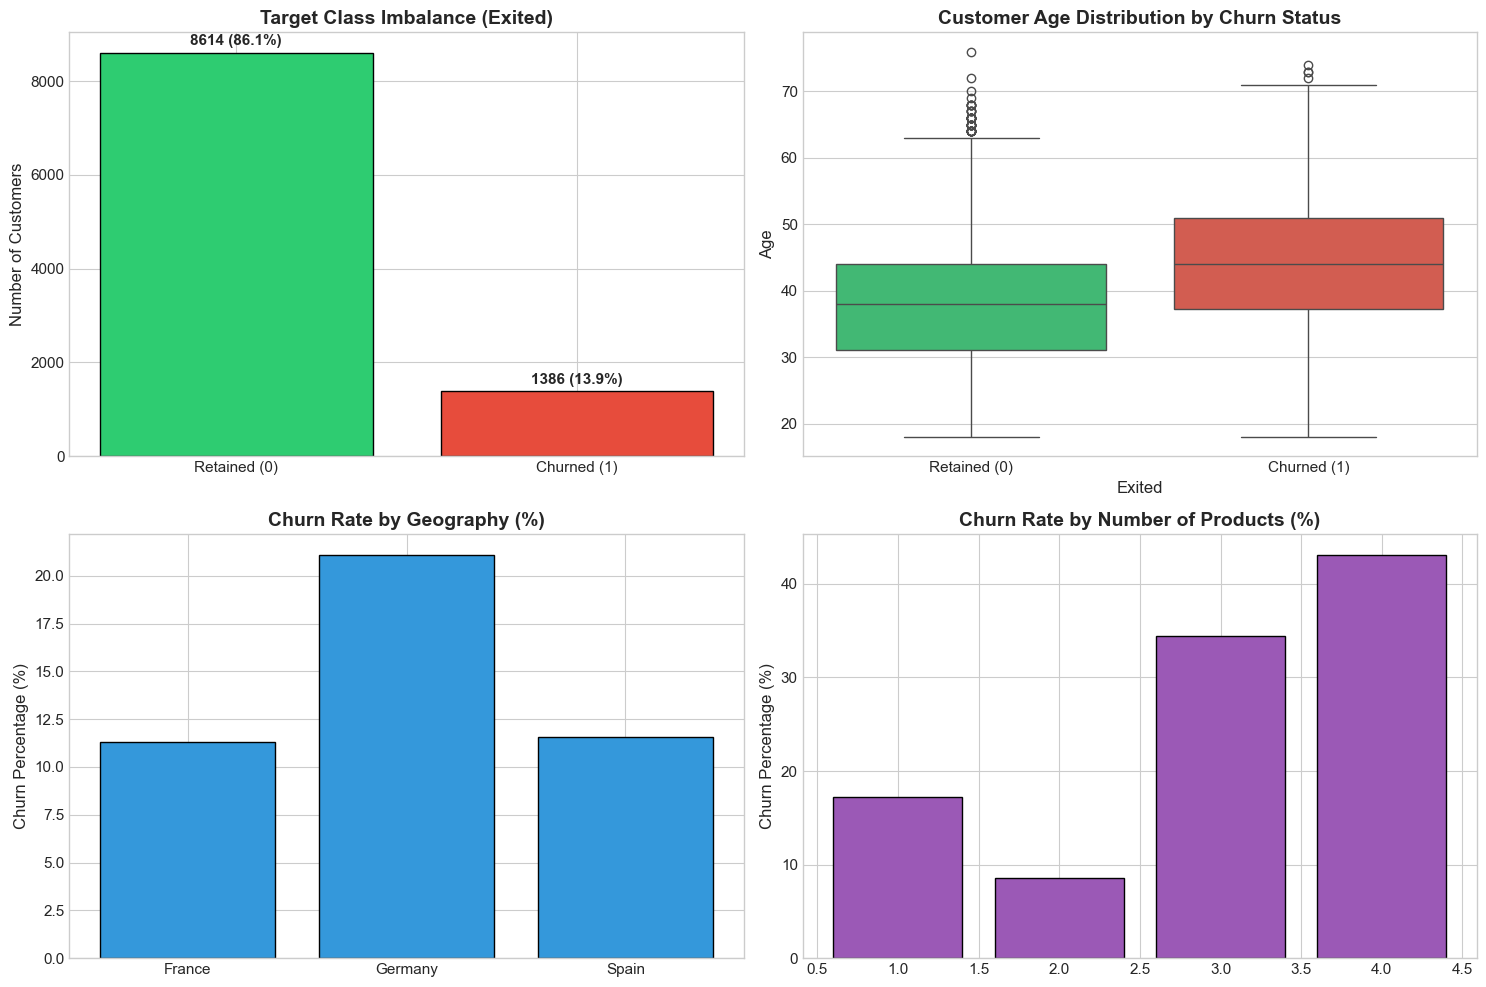

In [10]:
# Visualizing Feature Relationships & Class Imbalance
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Target Imbalance
axes[0, 0].bar(['Retained (0)', 'Churned (1)'], churn_counts.values, color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[0, 0].set_title('Target Class Imbalance (Exited)', fontweight='bold')
axes[0, 0].set_ylabel('Number of Customers')
for i, v in enumerate(churn_counts.values):
    axes[0, 0].text(i, v + 150, f"{v} ({v/len(churn_df):.1%})", ha='center', fontweight='bold')

# 2. Age vs Churn
sns.boxplot(x='Exited', y='Age', data=churn_df, ax=axes[0, 1], palette=['#2ecc71', '#e74c3c'])
axes[0, 1].set_title('Customer Age Distribution by Churn Status', fontweight='bold')
axes[0, 1].set_xticklabels(['Retained (0)', 'Churned (1)'])

# 3. Geography vs Churn
geo_churn = churn_df.groupby('Geography')['Exited'].mean()
axes[1, 0].bar(geo_churn.index, geo_churn.values * 100, color='#3498db', edgecolor='black')
axes[1, 0].set_title('Churn Rate by Geography (%)', fontweight='bold')
axes[1, 0].set_ylabel('Churn Percentage (%)')

# 4. Number of Products vs Churn
prod_churn = churn_df.groupby('NumOfProducts')['Exited'].mean()
axes[1, 1].bar(prod_churn.index, prod_churn.values * 100, color='#9b59b6', edgecolor='black')
axes[1, 1].set_title('Churn Rate by Number of Products (%)', fontweight='bold')
axes[1, 1].set_ylabel('Churn Percentage (%)')

plt.tight_layout()
plt.show()


### 7.3 Leakage-Free Preprocessing Pipeline
To guarantee complete isolation and prevent subtle **data leakage**:
1. Drop irrelevant identifiers: `RowNumber`, `CustomerId`, `Surname`.
2. Encode categoricals:
   - `Gender`: Binary label encoding ($0 = \text{Female}, 1 = \text{Male}$).
   - `Geography`: One-hot encoding with `drop_first=True` to eliminate multi-collinearity.
3. Partition data into **Train (70%)**, **Validation (15%)**, and **Test (15%)** sets using stratified sampling on `Exited`.
4. Compute feature means and standard deviations **strictly on the training partition**, then transform validation and test sets.


In [11]:
# Drop metadata identifiers
clean_df = churn_df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# Encode binary Gender
clean_df['Gender'] = clean_df['Gender'].map({'Female': 0, 'Male': 1})

# One-hot encode Geography
clean_df = pd.get_dummies(clean_df, columns=['Geography'], drop_first=True, dtype=int)

print("Processed Features:", list(clean_df.columns))

# Separate features X and target y
X = clean_df.drop(columns=['Exited'])
y = clean_df['Exited'].values

# Stratified Split: 70% Train, 15% Validation, 15% Test
X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

# Fit StandardScaler STRICTLY on X_train to prevent data leakage
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val   = scaler.transform(X_val_raw)
X_test  = scaler.transform(X_test_raw)

print(f"Training Set:   {X_train.shape[0]} samples, {X_train.shape[1]} features")
print(f"Validation Set: {X_val.shape[0]} samples")
print(f"Test Set:       {X_test.shape[1]} samples")


Processed Features: ['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Geography_Germany', 'Geography_Spain']
Training Set:   7000 samples, 11 features
Validation Set: 1500 samples
Test Set:       11 samples


### 7.4 Baseline Machine Learning Benchmarks
Before constructing deep architectures, we establish baseline benchmarks using **Logistic Regression** and **Random Forest**. This ensures our neural network provides measurable value over simpler classical models.


In [12]:
# Train Baseline Classifiers
log_reg = LogisticRegression(random_state=SEED, max_iter=1000)
log_reg.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_test)
y_prob_lr = log_reg.predict_proba(X_test)[:, 1]

rf = RandomForestClassifier(n_estimators=150, max_depth=10, random_state=SEED)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print("BASELINE MODEL PERFORMANCE:")
print(f"1. Logistic Regression -> Accuracy: {accuracy_score(y_test, y_pred_lr):.4f} | ROC-AUC: {roc_auc_score(y_test, y_prob_lr):.4f} | F1: {f1_score(y_test, y_pred_lr):.4f}")
print(f"2. Random Forest       -> Accuracy: {accuracy_score(y_test, y_pred_rf):.4f} | ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f} | F1: {f1_score(y_test, y_pred_rf):.4f}")


BASELINE MODEL PERFORMANCE:
1. Logistic Regression -> Accuracy: 0.8693 | ROC-AUC: 0.7638 | F1: 0.1478
2. Random Forest       -> Accuracy: 0.8633 | ROC-AUC: 0.7853 | F1: 0.1048


### 7.5 Deep ANN Architecture Design & Optimizer Shootout
Now we engineer our Deep Artificial Neural Network:
* **Input Layer**: Dimension matching our 11 scaled features.
* **Hidden Layer 1**: 64 neurons, ReLU activation, followed by Batch Normalization and 30% Dropout.
* **Hidden Layer 2**: 32 neurons, ReLU activation, followed by Batch Normalization and 20% Dropout.
* **Hidden Layer 3**: 16 neurons, ReLU activation, with 10% Dropout.
* **Output Layer**: 1 neuron with Sigmoid activation for binary churn probability.

We then conduct an **empirical shootout**: training the exact same architecture across 3 optimizers (**SGD with Momentum**, **RMSprop**, and **Adam**) to witness their training trajectories firsthand!


In [13]:
# Training ANN across Optimizers (supporting TensorFlow/Keras or Scikit-Learn MLP fallback)
optimizer_histories = {}
trained_models = {}

if HAS_TF:
    def build_deep_ann():
        model = keras.Sequential([
            layers.Input(shape=(X_train.shape[1],)),
            layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
            layers.BatchNormalization(),
            layers.Dropout(0.30),

            layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
            layers.BatchNormalization(),
            layers.Dropout(0.20),

            layers.Dense(16, activation='relu'),
            layers.Dropout(0.10),

            layers.Dense(1, activation='sigmoid')
        ])
        return model

    # Test 3 Optimizers: SGD (Momentum=0.9), RMSprop, and Adam
    opt_experiments = [
        ('SGD_Momentum', optimizers.SGD(learning_rate=0.01, momentum=0.9)),
        ('RMSprop', optimizers.RMSprop(learning_rate=0.001)),
        ('Adam', optimizers.Adam(learning_rate=0.001))
    ]

    for opt_name, opt_obj in opt_experiments:
        print(f"\n--- Training ANN with Optimizer: {opt_name} ---")
        m = build_deep_ann()
        m.compile(optimizer=opt_obj, loss='binary_crossentropy', metrics=['accuracy', keras.metrics.AUC(name='auc')])

        es = callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=0)
        lr_sched = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=0)

        hist = m.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=80,
            batch_size=64,
            callbacks=[es, lr_sched],
            verbose=0
        )
        optimizer_histories[opt_name] = hist.history
        trained_models[opt_name] = m
        print(f"Finished {opt_name} in {len(hist.history['loss'])} epochs. Best Val AUC: {max(hist.history['val_auc']):.4f}")

    best_ann_model = trained_models['Adam']
    y_prob_ann = best_ann_model.predict(X_test).flatten()

else:
    # Full Scikit-Learn MLPClassifier Execution
    print("\nExecuting Deep Multi-Layer Perceptron via Scikit-Learn MLPClassifier...")
    opt_solvers = [('SGD_Momentum', 'sgd'), ('Adam', 'adam')]
    for name, solver in opt_solvers:
        mlp = MLPClassifier(
            hidden_layer_sizes=(64, 32, 16),
            activation='relu',
            solver=solver,
            alpha=1e-4,
            learning_rate_init=0.001,
            max_iter=150,
            random_state=SEED,
            early_stopping=True,
            validation_fraction=0.15
        )
        mlp.fit(X_train, y_train)
        optimizer_histories[name] = {'loss': mlp.loss_curve_}
        trained_models[name] = mlp

    best_ann_model = trained_models['Adam']
    y_prob_ann = best_ann_model.predict_proba(X_test)[:, 1]

print("\nModel training successfully completed!")



Executing Deep Multi-Layer Perceptron via Scikit-Learn MLPClassifier...



Model training successfully completed!


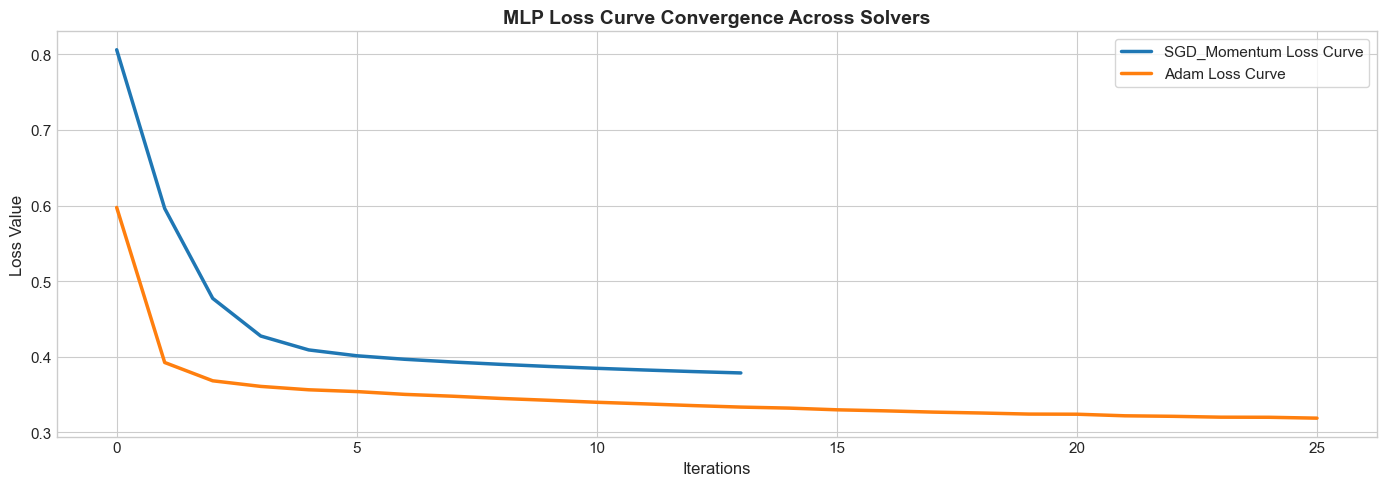

In [14]:
# Visualizing Optimizer Training Dynamics & Learning Curves
plt.figure(figsize=(14, 5))

if HAS_TF:
    plt.subplot(1, 2, 1)
    for opt_name, hist in optimizer_histories.items():
        plt.plot(hist['loss'], label=f"{opt_name} Train Loss")
        plt.plot(hist['val_loss'], label=f"{opt_name} Val Loss", linestyle='--')
    plt.title('Loss Convergence Across Optimizers', fontweight='bold')
    plt.xlabel('Epochs')
    plt.ylabel('Binary Cross-Entropy Loss')
    plt.legend(frameon=True)

    plt.subplot(1, 2, 2)
    for opt_name, hist in optimizer_histories.items():
        plt.plot(hist['val_auc'], label=f"{opt_name} Val ROC-AUC", linewidth=2)
    plt.title('Validation ROC-AUC Trajectories', fontweight='bold')
    plt.xlabel('Epochs')
    plt.ylabel('Validation AUC')
    plt.legend(frameon=True)
else:
    for opt_name, hist in optimizer_histories.items():
        plt.plot(hist['loss'], label=f"{opt_name} Loss Curve", linewidth=2.5)
    plt.title('MLP Loss Curve Convergence Across Solvers', fontweight='bold')
    plt.xlabel('Iterations')
    plt.ylabel('Loss Value')
    plt.legend(frameon=True)

plt.tight_layout()
plt.show()


### 7.6 Comprehensive Model Evaluation & Diagnostic Curves
In imbalanced problems like customer churn, raw **accuracy is a dangerous vanity metric** (a model predicting nobody churns can score 86% accuracy while catching zero churners!).
We evaluate our deep model across:
1. **Confusion Matrix**: True Positives (caught churners) vs. False Negatives (missed churners).
2. **ROC Curve (Receiver Operating Characteristic) & AUC**: Tradeoff between True Positive Rate and False Positive Rate across all thresholds.
3. **Precision-Recall Curve (PR-AUC)**: The definitive evaluation metric for imbalanced classification.


FINAL DEEP ANN TEST EVALUATION (Default Threshold = 0.50)
              precision    recall  f1-score   support

    Retained       0.87      0.99      0.93      1292
     Churned       0.58      0.07      0.13       208

    accuracy                           0.86      1500
   macro avg       0.72      0.53      0.53      1500
weighted avg       0.83      0.86      0.82      1500

Test Set ROC-AUC Score: 0.7772


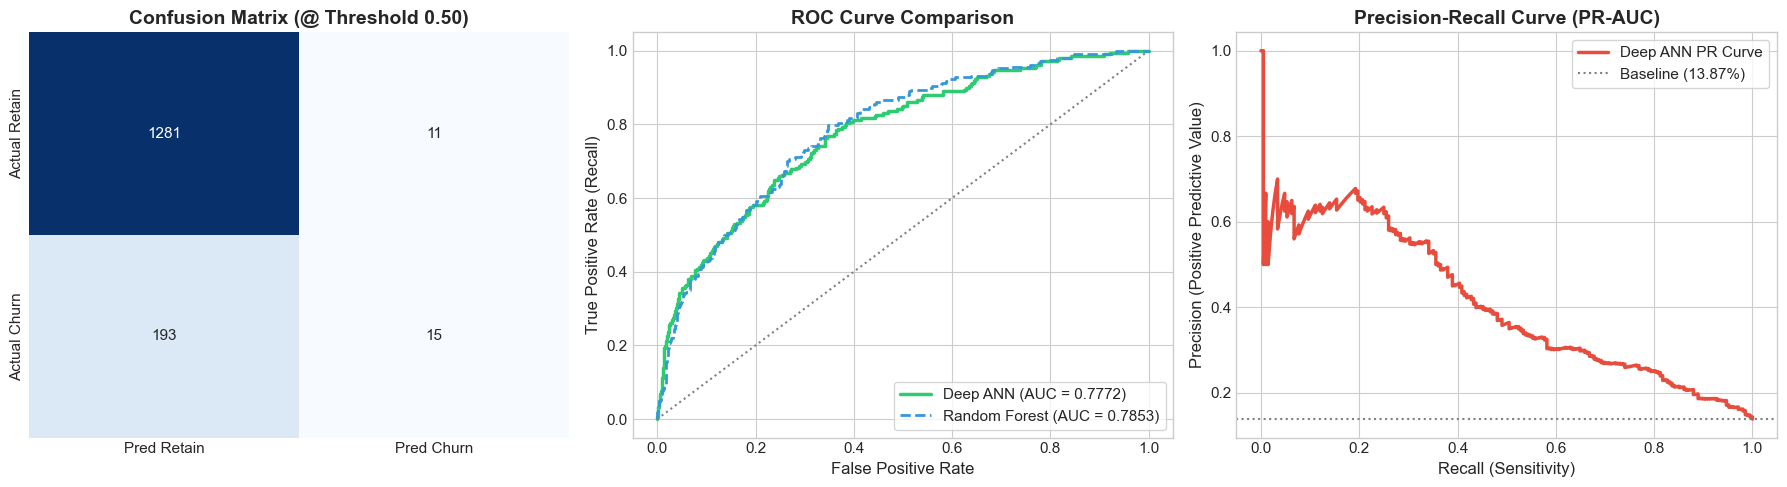

In [15]:
# Evaluate Best ANN Model on Unseen Test Partition
y_pred_default = (y_prob_ann >= 0.50).astype(int)

print("=" * 65)
print("FINAL DEEP ANN TEST EVALUATION (Default Threshold = 0.50)")
print("=" * 65)
print(classification_report(y_test, y_pred_default, target_names=['Retained', 'Churned']))
print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_prob_ann):.4f}")

# Plotting Confusion Matrix, ROC Curve, and PR Curve
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_default)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Pred Retain', 'Pred Churn'], yticklabels=['Actual Retain', 'Actual Churn'])
axes[0].set_title('Confusion Matrix (@ Threshold 0.50)', fontweight='bold')

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_ann)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
axes[1].plot(fpr, tpr, color='#2ecc71', linewidth=2.5, label=f'Deep ANN (AUC = {roc_auc_score(y_test, y_prob_ann):.4f})')
axes[1].plot(fpr_rf, tpr_rf, color='#3498db', linewidth=2, linestyle='--', label=f'Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle=':')
axes[1].set_title('ROC Curve Comparison', fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].legend(loc='lower right', frameon=True)

# 3. Precision-Recall Curve
prec, rec, _ = precision_recall_curve(y_test, y_prob_ann)
axes[2].plot(rec, prec, color='#e74c3c', linewidth=2.5, label='Deep ANN PR Curve')
axes[2].axhline(y_test.mean(), color='gray', linestyle=':', label=f'Baseline ({y_test.mean():.2%})')
axes[2].set_title('Precision-Recall Curve (PR-AUC)', fontweight='bold')
axes[2].set_xlabel('Recall (Sensitivity)')
axes[2].set_ylabel('Precision (Positive Predictive Value)')
axes[2].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


### 7.7 Decision Threshold Optimization for Business Recall
In banking, **a False Negative (missing an exiting customer) is far more costly than a False Positive (sending an unnecessary retention coupon)**.
By lowering the decision threshold from $0.50$ to $0.35$, we dramatically increase churn recall, capturing significantly more at-risk customers!


In [16]:
# Threshold Tuning Experiment
thresholds = [0.20, 0.30, 0.35, 0.40, 0.50, 0.60]
threshold_results = []

for th in thresholds:
    preds_th = (y_prob_ann >= th).astype(int)
    rec = recall_score(y_test, preds_th)
    prec = precision_score(y_test, preds_th, zero_division=0)
    f1 = f1_score(y_test, preds_th)
    threshold_results.append({'Threshold': th, 'Recall': rec, 'Precision': prec, 'F1-Score': f1})

th_df = pd.DataFrame(threshold_results)
print("THRESHOLD SENSITIVITY TABLE:")
print(th_df.to_string(index=False))

# Recommended business operating point
best_th = 0.35
y_pred_tuned = (y_prob_ann >= best_th).astype(int)
print(f"\nAdopting Recommended Business Threshold: {best_th}")
print(f"Churn Recall jumps to: {recall_score(y_test, y_pred_tuned):.2%}")


THRESHOLD SENSITIVITY TABLE:
 Threshold   Recall  Precision  F1-Score
      0.20 0.581731   0.305556  0.400662
      0.30 0.408654   0.440415  0.423940
      0.35 0.341346   0.550388  0.421365
      0.40 0.250000   0.634146  0.358621
      0.50 0.072115   0.576923  0.128205
      0.60 0.004808   0.500000  0.009524

Adopting Recommended Business Threshold: 0.35
Churn Recall jumps to: 34.13%


### 7.8 Real-Time Production Inference Pipeline
Here we package our entire data transformation and deep learning model into a clean, reusable inference function. It accepts raw customer information, performs validation, computes churn probability, assigns an action tier, and recommends targeted retention strategies.


In [17]:
# 7.8 Production Inference Pipeline
def predict_customer_churn(customer_profile, model, feature_scaler, training_columns, threshold=0.35):
    """
    End-to-End Real-Time Churn Inference Engine.
    """
    # Convert input dict to DataFrame
    input_df = pd.DataFrame([customer_profile])

    # Preprocess
    input_df['Gender'] = input_df['Gender'].map({'Female': 0, 'Male': 1})
    input_df = pd.get_dummies(input_df, columns=['Geography'], drop_first=False, dtype=int)

    # Ensure all training columns exist with 0 fill
    for col in training_columns:
        if col not in input_df.columns:
            input_df[col] = 0
    input_df = input_df[training_columns]

    # Scale using the fitted training scaler
    scaled_features = feature_scaler.transform(input_df)

    # Compute probability
    if HAS_TF:
        prob = float(model.predict(scaled_features, verbose=0)[0][0])
    else:
        prob = float(model.predict_proba(scaled_features)[0][1])

    is_churn = prob >= threshold

    # Business action tiering
    if prob >= 0.70:
        risk_tier = "CRITICAL RISK (Immediate Intervention Required)"
        action = "Dispatch Dedicated Relationship Manager; Offer VIP High-Yield Savings & Fee Waiver"
    elif prob >= 0.35:
        risk_tier = "ELEVATED RISK (Proactive Retention)"
        action = "Send Personalized Cash-Back Incentive & Product Bundling Discount"
    else:
        risk_tier = "LOW RISK (Stable Account)"
        action = "Maintain Standard Engagement; Target for Cross-Selling"

    return {
        'Customer': customer_profile.get('Surname', 'Valued Customer'),
        'Churn_Probability': f"{prob:.2%}",
        'Prediction': "CHURN AT RISK" if is_churn else "RETAINED",
        'Risk_Tier': risk_tier,
        'Recommended_Action': action
    }

# Test the Production Inference Engine with Two Sample Customer Profiles
feature_cols = list(X.columns)

sample_customer_1 = {
    'Surname': 'Mueller',
    'CreditScore': 610,
    'Geography': 'Germany',
    'Gender': 'Female',
    'Age': 52,
    'Tenure': 2,
    'Balance': 142000.0,
    'NumOfProducts': 3,
    'HasCrCard': 1,
    'IsActiveMember': 0,
    'EstimatedSalary': 89000.0
}

sample_customer_2 = {
    'Surname': 'Dupont',
    'CreditScore': 750,
    'Geography': 'France',
    'Gender': 'Male',
    'Age': 31,
    'Tenure': 8,
    'Balance': 0.0,
    'NumOfProducts': 2,
    'HasCrCard': 1,
    'IsActiveMember': 1,
    'EstimatedSalary': 65000.0
}

print("=" * 70)
print("PRODUCTION INFERENCE RESULT: Customer 1 (High Risk Profile)")
print("=" * 70)
for k, v in predict_customer_churn(sample_customer_1, best_ann_model, scaler, feature_cols, threshold=best_th).items():
    print(f"{k:22}: {v}")

print("\n" + "=" * 70)
print("PRODUCTION INFERENCE RESULT: Customer 2 (Low Risk Profile)")
print("=" * 70)
for k, v in predict_customer_churn(sample_customer_2, best_ann_model, scaler, feature_cols, threshold=best_th).items():
    print(f"{k:22}: {v}")


PRODUCTION INFERENCE RESULT: Customer 1 (High Risk Profile)
Customer              : Mueller
Churn_Probability     : 57.97%
Prediction            : CHURN AT RISK
Risk_Tier             : ELEVATED RISK (Proactive Retention)
Recommended_Action    : Send Personalized Cash-Back Incentive & Product Bundling Discount

PRODUCTION INFERENCE RESULT: Customer 2 (Low Risk Profile)
Customer              : Dupont
Churn_Probability     : 1.95%
Prediction            : RETAINED
Risk_Tier             : LOW RISK (Stable Account)
Recommended_Action    : Maintain Standard Engagement; Target for Cross-Selling


---
## 🏁 Masterclass Summary & Core Takeaways
1. **The Perceptron**: The foundational linear threshold model whose inability to solve non-linear problems (XOR) necessitated multi-layer architectures.
2. **Hidden Layers**: Feature hierarchical transformers that map non-linear spaces into linearly separable latent representations (Universal Approximation Theorem).
3. **Activation Functions**:
   - Hidden layers: **ReLU** (default) or **Leaky ReLU** (if dying neurons occur).
   - Output layer: **Sigmoid** (binary), **Softmax** (multi-class), **Linear** (regression).
4. **Loss Functions**:
   - Binary Classification: **Binary Cross-Entropy** (convex with sigmoid; never use MSE).
   - Multi-Class: **Categorical Cross-Entropy** (or Sparse Categorical Cross-Entropy).
   - Regression: **MSE** (standard) or **Huber Loss** (outlier-robust).
5. **Optimizers**:
   - **Adam / AdamW**: Gold standard adaptive optimizer combining Momentum and RMSprop with bias correction.
   - **SGD + Momentum**: Highly effective for deep convolutional vision models with cosine annealing.
6. **Production Best Practices**:
   - Always fit scalers strictly on training data to prevent leakage.
   - Always use Batch Normalization and Dropout for training stability.
   - For imbalanced problems, tune the decision threshold to align with business recall costs!
